# Notebook 2 — Transformer básico para series de tiempo


## 1. Marco conceptual

El **Transformer** (Vaswani et al., 2017, *Attention Is All You Need*) elimina la recurrencia: procesa **todos los pasos de la ventana en paralelo** y modela dependencias mediante **auto-atención**. Para series de tiempo basta con el bloque **encoder**:

| Componente | Función |
|---|---|
| **Embedding / proyección de entrada** | Lleva cada vector de 5 variables a una dimensión `d_model`. (En texto sería la tabla de embeddings de palabras.) |
| **Codificación posicional** | La auto-atención no sabe el orden; se suma una señal seno/coseno que indica la posición de cada paso. |
| **Multi-head self-attention** | Cada paso consulta a todos los demás. Varias "cabezas" aprenden relaciones distintas (p. ej. inmediata, diaria). |
| **Feed-forward (FFN)** | Red densa aplicada a cada posición. |
| **Residual + LayerNorm** | Estabilizan y facilitan el entrenamiento de redes profundas. |

**Ventajas frente a RNN/LSTM/GRU:** paralelización (entrenamiento más rápido), camino directo entre dos pasos cualesquiera (mejor para dependencias largas, sin desvanecimiento del gradiente) y pesos de atención interpretables. **Costo:** la atención crece como $O(T^2)$ con la longitud de la ventana.

$$\text{PE}_{(pos,2i)}=\sin\!\Big(\tfrac{pos}{10000^{2i/d}}\Big),\qquad \text{PE}_{(pos,2i+1)}=\cos\!\Big(\tfrac{pos}{10000^{2i/d}}\Big)$$

In [1]:
import math, io, json, os, time, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def savefig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

print("PyTorch:", torch.__version__, "| dispositivo:", device)
if device.type == "cpu":
    print("AVISO: activa una GPU en Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU")

PyTorch: 2.14.1+cpu | dispositivo: cpu
AVISO: activa una GPU en Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU


## 2. Datos: temperatura del clima de Jena (Alemania)

Se usa el dataset **Jena Climate 2009–2016** (Instituto Max Planck de Biogeoquímica). Tiene mediciones meteorológicas cada 10 minutos. Para esta actividad:

- Se toma **solo la variable temperatura del aire `T (degC)`**.
- Se submuestrea a **una lectura por hora** (cada 6 registros), lo que da ~70.000 observaciones y una serie más manejable.
- **Tarea de predicción:** dada la temperatura de las **últimas 72 horas** (3 días), predecir la de las **próximas 24 horas** (pronóstico multi-paso).

In [2]:
URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
raw = urllib.request.urlopen(URL).read()
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    df = pd.read_csv(z.open("jena_climate_2009_2016.csv"))

df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
df = df.iloc[5::6].reset_index(drop=True)          # 1 registro por hora
df = df[["Date Time", "T (degC)"]].rename(columns={"Date Time": "fecha", "T (degC)": "temp"})

print("Registros (horarios):", len(df))
print("Rango:", df["fecha"].min(), "->", df["fecha"].max())
print("Valores nulos:", int(df["temp"].isna().sum()))
print("Frecuencias distintas entre registros:", df["fecha"].diff().value_counts().head(3).to_dict())
df["temp"].describe().round(2)

Registros (horarios): 70091
Rango: 2009-01-01 01:00:00 -> 2016-12-31 23:10:00
Valores nulos: 0
Frecuencias distintas entre registros: {Timedelta('0 days 01:00:00'): 70083, Timedelta('0 days 01:10:00'): 2, Timedelta('0 days 01:20:00'): 1}


,temp
count,70091.00
mean,9.45
std,8.42
min,-22.76
25%,3.35
50%,9.41
75%,15.48
max,37.28


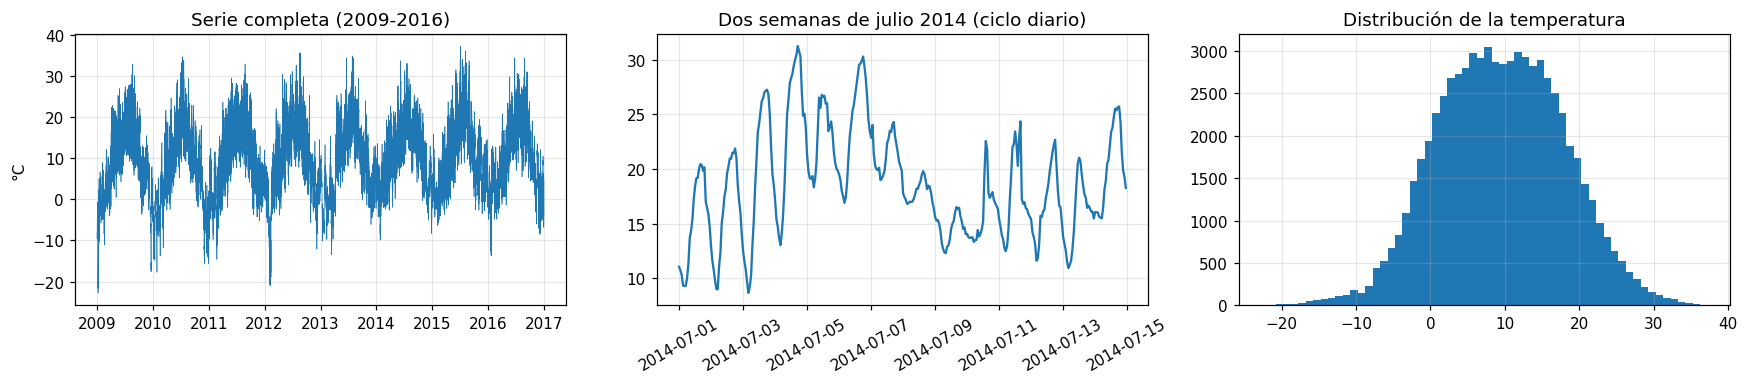

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].plot(df["fecha"], df["temp"], lw=0.4)
ax[0].set_title("Serie completa (2009-2016)"); ax[0].set_ylabel("°C")
m = df[(df["fecha"] >= "2014-07-01") & (df["fecha"] < "2014-07-15")]
ax[1].plot(m["fecha"], m["temp"]); ax[1].set_title("Dos semanas de julio 2014 (ciclo diario)")
ax[1].tick_params(axis="x", rotation=30)
ax[2].hist(df["temp"], bins=60); ax[2].set_title("Distribución de la temperatura")
plt.tight_layout(); savefig("01_eda"); plt.show()

## 3. Preprocesamiento

1. **Variables de entrada (5 por paso de tiempo):** la temperatura y una codificación cíclica de la **hora del día** y del **día del año** (seno y coseno). Así el modelo conoce la posición temporal sin tratarla como un número lineal (la hora 23 está cerca de la 0).
2. **Partición cronológica** 70 % / 15 % / 15 % (entrenamiento / validación / prueba). No se mezclan al azar para **evitar fuga de información** del futuro al pasado.
3. **Normalización (z-score)** con media y desviación calculadas **solo con el conjunto de entrenamiento**.
4. **Ventanas deslizantes:** cada muestra es `X ∈ R^(72×5)` y su objetivo `y ∈ R^24` (temperatura normalizada de las siguientes 24 h).

In [4]:
LOOKBACK, HORIZON = 72, 24
BATCH = 256

temp = df["temp"].values.astype(np.float64)
hour = df["fecha"].dt.hour.values
doy = df["fecha"].dt.dayofyear.values

n = len(temp)
i_tr, i_va = int(n * 0.70), int(n * 0.85)

mu, sd = temp[:i_tr].mean(), temp[:i_tr].std()      # solo con entrenamiento
temp_s = (temp - mu) / sd
feats = np.column_stack([
    temp_s,
    np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24),
    np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25),
])
N_FEATS = feats.shape[1]

def make_windows(f, target, lookback, horizon):
    k = len(f) - lookback - horizon + 1
    ix = np.arange(k)[:, None] + np.arange(lookback)[None, :]
    iy = np.arange(k)[:, None] + lookback + np.arange(horizon)[None, :]
    return f[ix].astype(np.float32), target[iy].astype(np.float32)

Xtr, ytr = make_windows(feats[:i_tr], temp_s[:i_tr], LOOKBACK, HORIZON)
Xva, yva = make_windows(feats[i_tr:i_va], temp_s[i_tr:i_va], LOOKBACK, HORIZON)
Xte, yte = make_windows(feats[i_va:], temp_s[i_va:], LOOKBACK, HORIZON)

print(f"media={mu:.2f} °C  desv={sd:.2f} °C")
print("train:", Xtr.shape, ytr.shape, "| val:", Xva.shape, "| test:", Xte.shape)

train_loader = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)), batch_size=BATCH, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.from_numpy(Xva), torch.from_numpy(yva)), batch_size=1024)

media=9.11 °C  desv=8.65 °C
train: (48968, 72, 5) (48968, 24) | val: (10419, 72, 5) | test: (10419, 72, 5)


## 4. Implementación del Transformer (encoder)

Se construye cada pieza **desde cero** con PyTorch (sin `nn.TransformerEncoder`) para exponer los pesos de atención.

Arquitectura: `Linear(5→d_model)` → `+ PE` → **N bloques encoder** → se combinan el último paso y el promedio de todos los pasos → capa densa → 24 predicciones.

In [5]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))        # (1, max_len, d_model)

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model debe ser divisible por n_heads"
        self.h, self.dk = n_heads, d_model // n_heads
        self.q, self.k, self.v = nn.Linear(d_model, d_model), nn.Linear(d_model, d_model), nn.Linear(d_model, d_model)
        self.o = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):                                   # x (B,T,D)
        B, T, _ = x.shape
        split = lambda t: t.view(B, T, self.h, self.dk).transpose(1, 2)    # (B,h,T,dk)
        Q, K, V = split(self.q(x)), split(self.k(x)), split(self.v(x))
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.dk)             # (B,h,T,T)
        w = torch.softmax(scores, dim=-1)
        out = (self.drop(w) @ V).transpose(1, 2).contiguous().view(B, T, -1)
        return self.o(out), w


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadSelfAttention(d_model, n_heads, dropout)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        a, w = self.attn(x)
        x = self.norm1(x + self.drop(a))                    # residual + LayerNorm
        x = self.norm2(x + self.drop(self.ffn(x)))          # residual + LayerNorm
        return x, w


class TimeSeriesTransformer(nn.Module):
    def __init__(self, n_feats, horizon=24, d_model=64, n_heads=4, n_layers=2, d_ff=128, dropout=0.1):
        super().__init__()
        self.inp = nn.Linear(n_feats, d_model)
        self.pos = PositionalEncoding(d_model)
        self.layers = nn.ModuleList([EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.head = nn.Sequential(nn.Linear(2 * d_model, d_model), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_model, horizon))

    def forward(self, x, return_attn=False):
        x = self.pos(self.inp(x))
        attns = []
        for layer in self.layers:
            x, w = layer(x)
            attns.append(w)
        z = torch.cat([x[:, -1], x.mean(dim=1)], dim=-1)    # último paso + promedio de la ventana
        out = self.head(z)
        return (out, attns) if return_attn else out


class GRUBaseline(nn.Module):
    """GRU simple para comparar con el Transformer."""
    def __init__(self, n_feats, hidden=64, horizon=24, dropout=0.1):
        super().__init__()
        self.gru = nn.GRU(n_feats, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, horizon))
    def forward(self, x):
        _, h = self.gru(x)
        return self.head(h[-1])

model_tr = TimeSeriesTransformer(N_FEATS, horizon=HORIZON)
model_gru = GRUBaseline(N_FEATS, horizon=HORIZON)
print(model_tr)

TimeSeriesTransformer(
  (inp): Linear(in_features=5, out_features=64, bias=True)
  (pos): PositionalEncoding()
  (layers): ModuleList(
    (0-1): 2 x EncoderLayer(
      (attn): MultiHeadSelfAttention(
        (q): Linear(in_features=64, out_features=64, bias=True)
        (k): Linear(in_features=64, out_features=64, bias=True)
        (v): Linear(in_features=64, out_features=64, bias=True)
        (o): Linear(in_features=64, out_features=64, bias=True)
        (drop): Dropout(p=0.1, inplace=False)
      )
      (ffn): Sequential(
        (0): Linear(in_features=64, out_features=128, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=128, out_features=64, bias=True)
      )
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (drop): Dropout(p=0.1, inplace=False)
    )
  )
  (head): Sequential(
    (0): Linear(in_features

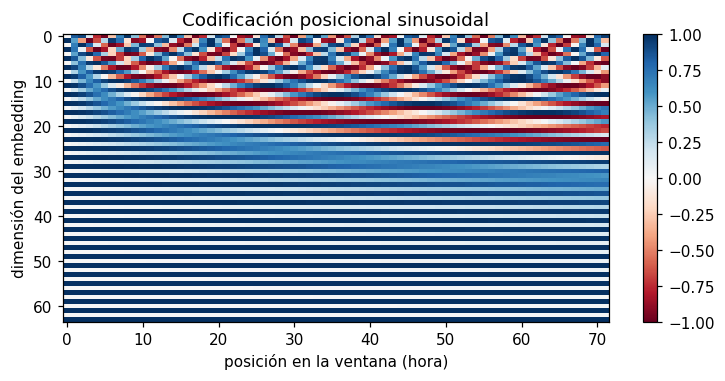

In [6]:
# Visualización de la codificación posicional
pe = PositionalEncoding(64).pe[0, :LOOKBACK].numpy()
plt.figure(figsize=(8, 3.4)); plt.imshow(pe.T, aspect="auto", cmap="RdBu"); plt.colorbar()
plt.xlabel("posición en la ventana (hora)"); plt.ylabel("dimensión del embedding"); plt.title("Codificación posicional sinusoidal")
plt.grid(False); savefig("02_codificacion_posicional"); plt.show()

## 5. Entrenamiento
Mismo procedimiento que en el Notebook 1 (Adam, MSE, *clipping*, *early stopping*). Para el Transformer se usa una tasa de aprendizaje menor (5e-4). **Usa GPU (T4).**

In [9]:
def train_model(model, name, epochs=5, lr=1e-3, patience=6):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    loss_fn = nn.MSELoss()
    hist = {"train": [], "val": []}
    best, best_state, wait = float("inf"), None, 0
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"[{name}] parámetros entrenables: {n_params:,}")
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl, cnt = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tl += loss.item() * len(xb); cnt += len(xb)
        model.eval(); vl, vc = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                vl += loss_fn(model(xb), yb).item() * len(xb); vc += len(xb)
        tl, vl = tl / cnt, vl / vc
        hist["train"].append(tl); hist["val"].append(vl); sched.step(vl)
        print(f"  época {ep:02d} | train MSE {tl:.4f} | val MSE {vl:.4f}")
        if vl < best - 1e-5:
            best, wait = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                print(f"  early stopping en la época {ep}"); break
    model.load_state_dict(best_state)
    print(f"[{name}] mejor val MSE = {best:.4f} | tiempo = {time.time() - t0:.0f} s")
    return hist

@torch.no_grad()
def predict(model, X, bs=1024):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model(torch.from_numpy(X[i:i + bs]).to(device)).cpu().numpy())
    return np.concatenate(out)

def to_c(a):                       # de z-score a °C
    return a * sd + mu

def evaluate(pred_s, true_s):
    p, t = to_c(pred_s), to_c(true_s)
    err = p - t
    return {"MAE": float(np.abs(err).mean()), "RMSE": float(np.sqrt((err ** 2).mean())),
            "MAE_por_hora": np.abs(err).mean(0)}

In [10]:
histories = {}
histories["GRU"] = train_model(model_gru, "GRU", lr=1e-3)
histories["Transformer"] = train_model(model_tr, "Transformer", lr=5e-4)

[GRU] parámetros entrenables: 19,352
  época 01 | train MSE 0.0872 | val MSE 0.0870
  época 02 | train MSE 0.0870 | val MSE 0.0866
  época 03 | train MSE 0.0863 | val MSE 0.0870
  época 04 | train MSE 0.0862 | val MSE 0.0861
  época 05 | train MSE 0.0855 | val MSE 0.0868
[GRU] mejor val MSE = 0.0861 | tiempo = 97 s
[Transformer] parámetros entrenables: 77,144
  época 01 | train MSE 0.0962 | val MSE 0.0941
  época 02 | train MSE 0.0937 | val MSE 0.0902
  época 03 | train MSE 0.0922 | val MSE 0.0918
  época 04 | train MSE 0.0911 | val MSE 0.0910
  época 05 | train MSE 0.0902 | val MSE 0.0917
[Transformer] mejor val MSE = 0.0902 | tiempo = 747 s


## 6. Evaluación en el conjunto de prueba

In [11]:
results = {}
pred_persist = np.repeat(Xte[:, -1, 0:1], HORIZON, axis=1)
results["Persistencia"] = evaluate(pred_persist, yte)
pred_gru = predict(model_gru, Xte);  results["GRU"] = evaluate(pred_gru, yte)
pred_tr = predict(model_tr, Xte);    results["Transformer"] = evaluate(pred_tr, yte)

tabla = pd.DataFrame({k: {"MAE (°C)": v["MAE"], "RMSE (°C)": v["RMSE"]} for k, v in results.items()}).T.round(3)
display(tabla)
json.dump({k: {"MAE": v["MAE"], "RMSE": v["RMSE"]} for k, v in results.items()}, open("resultados_notebook2.json", "w"), indent=2)

,MAE (°C),RMSE (°C)
Persistencia,3.158,4.271
GRU,1.818,2.411
Transformer,1.873,2.456


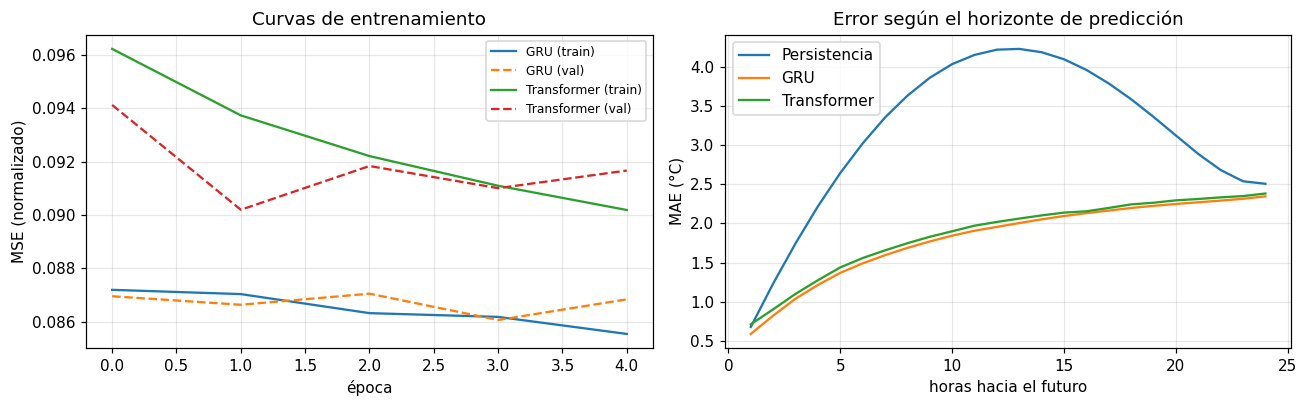

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, h in histories.items():
    ax[0].plot(h["train"], label=f"{name} (train)"); ax[0].plot(h["val"], "--", label=f"{name} (val)")
ax[0].set_xlabel("época"); ax[0].set_ylabel("MSE (normalizado)"); ax[0].set_title("Curvas de entrenamiento"); ax[0].legend(fontsize=8)
for name, r in results.items():
    ax[1].plot(range(1, HORIZON + 1), r["MAE_por_hora"], label=name)
ax[1].set_xlabel("horas hacia el futuro"); ax[1].set_ylabel("MAE (°C)"); ax[1].set_title("Error según el horizonte de predicción"); ax[1].legend()
plt.tight_layout(); savefig("curvas_y_error_horizonte"); plt.show()

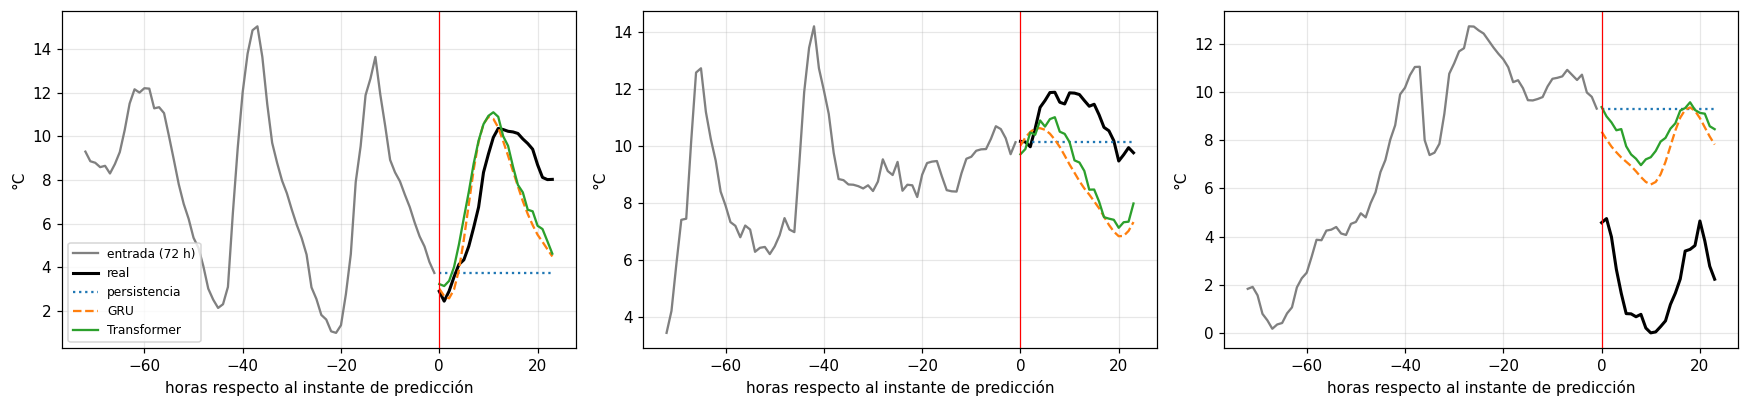

In [13]:
idx = [200, 1500, 3000]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, i in zip(axes, idx):
    ax.plot(range(-LOOKBACK, 0), to_c(Xte[i, :, 0]), color="gray", label="entrada (72 h)")
    ax.plot(range(0, HORIZON), to_c(yte[i]), "k", lw=2, label="real")
    ax.plot(range(0, HORIZON), to_c(pred_persist[i]), ":", label="persistencia")
    ax.plot(range(0, HORIZON), to_c(pred_gru[i]), "--", label="GRU")
    ax.plot(range(0, HORIZON), to_c(pred_tr[i]), label="Transformer")
    ax.axvline(0, color="red", lw=0.8); ax.set_xlabel("horas respecto al instante de predicción"); ax.set_ylabel("°C")
axes[0].legend(fontsize=8); plt.tight_layout(); savefig("pronosticos_ejemplo"); plt.show()

## 7. Análisis de la auto-atención
Se inspeccionan los pesos de la **última capa**: (a) mapa de auto-atención de cada cabeza para una muestra y (b) a qué horas mira, en promedio, la **última posición** (la más reciente) de la ventana.

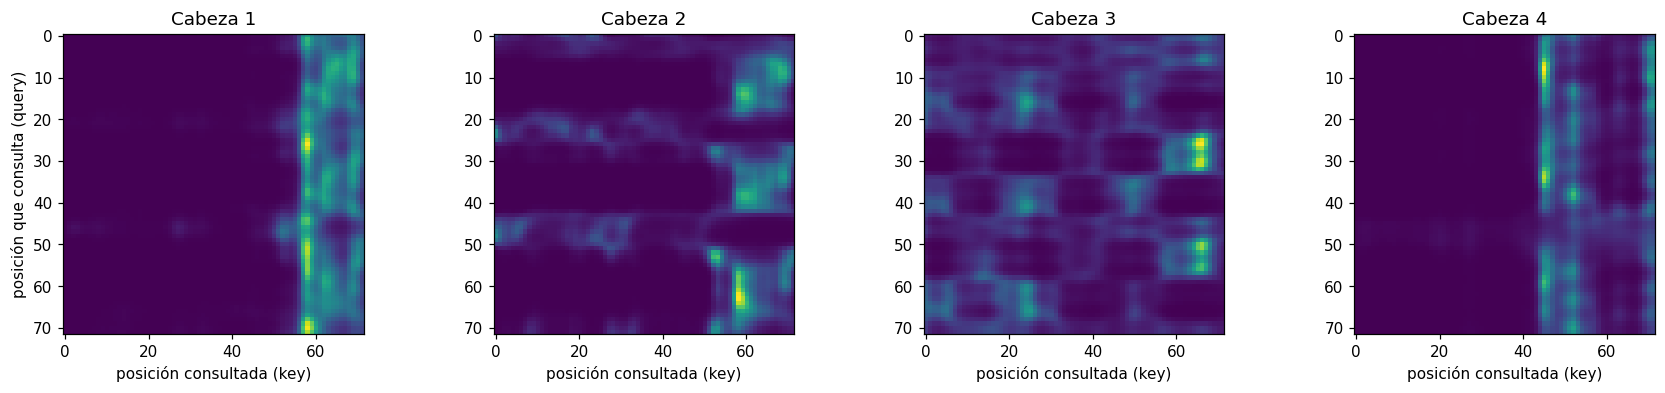

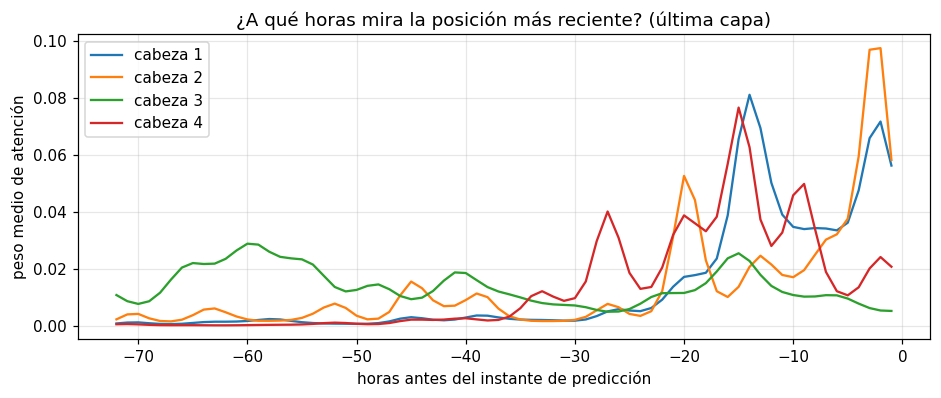

In [14]:
model_tr.eval()
with torch.no_grad():
    _, attns = model_tr(torch.from_numpy(Xte[:2000]).to(device), return_attn=True)
A = attns[-1].cpu().numpy()                                   # (muestras, cabezas, T, T)
n_heads = A.shape[1]

fig, axes = plt.subplots(1, n_heads, figsize=(4 * n_heads, 3.6))
for h in range(n_heads):
    axes[h].imshow(A[0, h], cmap="viridis"); axes[h].set_title(f"Cabeza {h + 1}")
    axes[h].set_xlabel("posición consultada (key)"); axes[h].grid(False)
axes[0].set_ylabel("posición que consulta (query)")
plt.tight_layout(); savefig("atencion_cabezas"); plt.show()

last_q = A[:, :, -1, :].mean(0)                               # (cabezas, T): atención de la posición más reciente
plt.figure(figsize=(10, 3.6))
for h in range(n_heads):
    plt.plot(range(-LOOKBACK, 0), last_q[h], label=f"cabeza {h + 1}")
plt.xlabel("horas antes del instante de predicción"); plt.ylabel("peso medio de atención")
plt.title("¿A qué horas mira la posición más reciente? (última capa)"); plt.legend(); savefig("atencion_ultima_posicion"); plt.show()

In [15]:
print("RESUMEN FINAL (conjunto de prueba, °C)")
print(tabla.to_markdown() if hasattr(tabla, "to_markdown") else tabla)
print("\nParámetros -> GRU:", sum(p.numel() for p in model_gru.parameters()),
      "| Transformer:", sum(p.numel() for p in model_tr.parameters()))

RESUMEN FINAL (conjunto de prueba, °C)
|              |   MAE (°C) |   RMSE (°C) |
|:-------------|-----------:|------------:|
| Persistencia |      3.158 |       4.271 |
| GRU          |      1.818 |       2.411 |
| Transformer  |      1.873 |       2.456 |

Parámetros -> GRU: 19352 | Transformer: 77144
